# LSTM Practice Implementation

In [1]:
#Run from the start if training a new model, current architecture is 128 hidden layer size, 3 layers, 4 input features, 2 output features.
#Or load in model weights model, under "Instantiating Model" heading.

## Configuring MPS

In [2]:
import torch
import torch.nn as nn

#Set the device automatically: Cuda/Mps
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: mps


## Viewing the CSV

In [3]:
import pandas as pd

df = pd.read_csv("rdb5_data.csv")

df.head(5)

/var/folders/cj/rxl_zw1j7jz82tt4ktrl_w040000gn/T/ipykernel_65357/3545351190.py:3: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("rdb5_data.csv")


,ID,TIMESTAMP,OBJID,UTM_X,UTM_Y,UTM_ANGLE,V,ACC,ACC_LAT,ACC_TAN,CLASS,WIDTH,LENGTH,TRAILER_ID
0,1,0.000000,57687,617396.68,5806787.75,1.526085,7.64,0.7646,-0.7640,0.0323,Car,2.0149,4.4885,NaN
1,2,0.033367,57687,617396.69,5806788.00,1.529885,7.64,0.8675,-0.8671,0.0253,Car,2.0149,4.4885,NaN
2,3,0.066733,57687,617396.69,5806788.26,1.533185,7.64,0.9703,-0.9702,0.0158,Car,2.0149,4.4885,NaN
3,4,0.100100,57687,617396.70,5806788.51,1.536085,7.64,1.0743,-1.0743,-0.0071,Car,2.0149,4.4885,NaN
4,5,0.133467,57687,617396.70,5806788.77,1.538885,7.64,1.1802,-1.1794,-0.0434,Car,2.0149,4.4885,NaN


In [4]:
#considering vehicle classes
print(df['CLASS'].value_counts())

CLASS
Car               1262670
Pedestrian         185361
Medium Vehicle     148991
Bicycle             79396
Heavy Vehicle       38987
Trailer             33846
Bus                 14498
Motorcycle           3274
Name: count, dtype: int64


## Filtering the Data

In [5]:
#keeping only vehicle classes
vehicle_classes = [
    "Car",
    "Medium Vehicle",
    "Trailer",
    "Bus",
    "Heavy Vehicle",
    "Motorcycle"
]

df = df[df["CLASS"].isin(vehicle_classes)]

In [6]:
#verification
print(df["CLASS"].value_counts())

CLASS
Car               1262670
Medium Vehicle     148991
Heavy Vehicle       38987
Trailer             33846
Bus                 14498
Motorcycle           3274
Name: count, dtype: int64


In [7]:
#removal of less the 150 object observations
trajectory_lengths = df.groupby("OBJID").size()
valid_objids = trajectory_lengths[trajectory_lengths >= 150].index
df = df[df["OBJID"].isin(valid_objids)]

## Creating Sliding Windows

In [8]:
import numpy as np

def make_windows(positions, input_length=60, target_length=90, stride=10):
    inputs = []
    targets = []

    total_length = input_length + target_length

    for start in range(0, len(positions) - total_length + 1, stride):
        #set current window
        window = positions[start: (start + total_length)]

        #split window into input and target (60/90)
        #input is more than just position (other features so far: angle, output remains just position 
        input_data = window[:input_length]
        target_positions = window[input_length:]

        origin = input_data[0, :2]

        #just subtract from x and y coords, don't confuse with angle
        input_relative = input_data[:, :2] - origin
        target_relative = target_positions[:, :2] - origin

        #adding angle as a feature
        initial_angle = input_data[0, 2]
        relative_angle = input_data[:, 2] - initial_angle

        #np.sin and cos expect angle in radians
        relative_angle = np.deg2rad(relative_angle)

        #sin/cos encoding
        angle_sin = np.sin(relative_angle)
        angle_cos = np.cos(relative_angle)

        #combine x, y, sin(angle), cos(angle) together as input features
        input_features = np.column_stack((
            input_relative,
            angle_sin,
            angle_cos
        ))

        inputs.append(input_features)
        targets.append(target_relative)

    return inputs, targets

## Define Dividing Vehicle IDs into Train/Validate/Test Splits

In [9]:
#define train, validate, test split (70/15/15) by objectID so same vehicle isn't used in train and test (cheating)
import numpy as np

#create array of only unique vehicles, to ensure all observations from the same vehicle remain in the same train, val or test set 
vehicle_ids = df["OBJID"].unique()

np.random.seed(1)

np.random.shuffle(vehicle_ids)

n = len(vehicle_ids)

#splitting the vehicle ids between sets
train_ids = vehicle_ids[:int(0.7 * n)]
val_ids = vehicle_ids[int(0.7 * n):int(0.85 * n)]
test_ids = vehicle_ids[int(0.85 * n):]

#verification
print(len(train_ids))
print(len(val_ids))
print(len(test_ids))

2808
602
602


## Making Train, Val and Test Sets

In [10]:
def create_dataset(df, vehicle_ids):
    inputs = []
    targets = []
    metadata = []

    for objid in vehicle_ids:
        #get all obserations of just one vehicle from the df
        vehicle = df[df["OBJID"] == objid]

        #get the just the features of importance (x and y pos) and now angle
        positions = vehicle[["UTM_X", "UTM_Y", "UTM_ANGLE"]].values

        #get the first 60 observations of each window and following 90.
        vehicle_inputs, vehicle_targets = make_windows(positions)

        inputs.extend(vehicle_inputs)
        targets.extend(vehicle_targets)

        #tracking where each window came from
        for start in range(0, len(positions) - 150 + 1, 10):
            metadata.append((objid, start))

    return inputs, targets, metadata

In [11]:
# defining each set through the create dataset function using the df and the specific ids attatched to each set
#now includes metadata for tracking real-world starting location 
train_inputs, train_targets, train_metadata = create_dataset(df, train_ids)
val_inputs, val_targets, val_metadata = create_dataset(df, val_ids)
test_inputs, test_targets, test_metadata = create_dataset(df, test_ids)

#validation
print("Train:", len(train_inputs))
print("Validation:", len(val_inputs))
print("Test:", len(test_inputs))

Train: 64452
Validation: 13912
Test: 13515


## Converting Data to PyTorch Tensors

In [12]:
#converting to tensors for pytorch use
train_inputs = torch.tensor(train_inputs, dtype=torch.float32)
train_targets = torch.tensor(train_targets, dtype=torch.float32)

val_inputs = torch.tensor(val_inputs, dtype=torch.float32)
val_targets = torch.tensor(val_targets, dtype=torch.float32)

test_inputs = torch.tensor(test_inputs, dtype=torch.float32)
test_targets = torch.tensor(test_targets, dtype=torch.float32)

# #verification
print(train_inputs.shape)
print(train_targets.shape)
print(val_inputs.shape)
print(val_targets.shape)
print(test_inputs.shape)
print(test_targets.shape)

/var/folders/cj/rxl_zw1j7jz82tt4ktrl_w040000gn/T/ipykernel_65357/1751556688.py:2: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:255.)
  train_inputs = torch.tensor(train_inputs, dtype=torch.float32)


torch.Size([64452, 60, 4])
torch.Size([64452, 90, 2])
torch.Size([13912, 60, 4])
torch.Size([13912, 90, 2])
torch.Size([13515, 60, 4])
torch.Size([13515, 90, 2])


## Making PyTorch Dataset

In [13]:
#the dataset stores data examples and their corresponding labels
#and gives us one example at a time
from torch.utils.data import Dataset

class TrajectoryDataset(Dataset):
    def __init__(self, inputs, targets):
        self.inputs = inputs
        self.targets = targets

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, index):
        return self.inputs[index], self.targets[index]

In [14]:
train_dataset = TrajectoryDataset(train_inputs, train_targets)
val_dataset = TrajectoryDataset(val_inputs, val_targets)
test_dataset = TrajectoryDataset(test_inputs, test_targets)

## Making Pytorch Dataloader

In [15]:
# DataLoader groups examples into batches
from torch.utils.data import DataLoader

# Only shuffle the training data so the model get examples
# in a different order each epoch
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

## Defining LSTM Architecture

In [16]:
class TrajectoryLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=4,
            hidden_size=128, #sensible moderate hyperparameter, however, may change during validation
            num_layers=2,
            batch_first=True
        )

        self.linear = nn.Linear(128, 180)

        #this direct-prediction architecture is a simplified starting point, sequence to sequence may be better later
        #direct prediction: predict all 90 future locations
        #sequence-to-sequence: predict future locations one at a time
        
    def forward(self, x):
        #pass the input through the LSTM
        output, (hidden, cell) = self.lstm(x)
    
        # #remove the unnecessary layer dimension ONLY works when layer dimension is 1
        # hidden = hidden.squeeze(0)

        #get just last element instead of removing first layer dimenion
        hidden = hidden[-1]
    
        #produce 180 numbers
        output = self.linear(hidden)
    
        #turn those 180 numbers into coordinates, -1 in case last batch size isn't the full 32
        output = output.reshape(-1, 90, 2)
    
        return output

## Instantiating Model

In [17]:
model = TrajectoryLSTM()
model = model.to(device)

print(model.load_state_dict(torch.load('4-feature-models/h128_n2_e100_f4.pt', weights_only=True)))

<All keys matched successfully>


## Defining Loss Function (MSE)

In [18]:
#returns PyTorch Tensor, because PyTorch needs to track the computational graph so that it can later calc gradients
#computational graph is the trail of how the value came to be input->LSTM->prediction->MSEloss
#loss.item() gives the associated float
loss_fn = nn.MSELoss()

## Optimiser

In [19]:
#utilising PyTorch's Adam Optimiser 
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## Multiple Epochs

In [20]:
run_epochs = False

if run_epochs:
    num_epochs = 100
    losses = []
    
    for epoch in range(num_epochs):
    
        model.train()
    
        total_loss = 0
    
        for x_batch, y_batch in train_loader:
    
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
    
            optimizer.zero_grad()
    
            prediction = model(x_batch)
    
            loss = loss_fn(prediction, y_batch)
    
            loss.backward()
    
            optimizer.step()
    
            total_loss += loss.item()
    
        average_loss = total_loss / len(train_loader)
        
        losses.append(average_loss)
    
        print("Epoch:", epoch + 1, "Training loss:", average_loss)

## Graphing Loss vs Epoch

In [21]:
if run_epochs:
    import matplotlib.pyplot as plt
    plt.close()
    plt.plot(range(1, num_epochs + 1), losses)
    
    plt.xlabel("Epoch Number")
    plt.ylabel("Training Loss (MSE)")
    plt.title("Training Loss per Epoch")
    
    plt.show()

## Model Evaluation

In [22]:
#print(model.load_state_dict(torch.load('h128_n1_e100_f4.pt', weights_only=True)))

model.eval()

total_loss = 0

#no gradient calculation/ model is not changing
with torch.no_grad():

    for x_batch, y_batch in val_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        prediction = model(x_batch)

        loss = loss_fn(prediction, y_batch)

        total_loss += loss.item()

average_val_loss = total_loss / len(val_loader)

print("Validation loss:", average_val_loss)

Validation loss: 0.6169695520538023


## Saving Pretrained Models

In [23]:
#Path is h<hidden layer size>_n<num_ber of layers>_e<number of epochs>_f<number_of_input_features>.pt

#model_name = "4-feature-models/h64_n3_e60_f4.pt"
#torch.save(model.state_dict(), model_name)

# Inference of Unseen Trajectory

### (Hand-picked for Visualisation Purposes)

In [106]:
test_vehicle_index = 120

x_test = test_inputs[test_vehicle_index]
y_test = test_targets[test_vehicle_index]

#unsqueeze to allow a single example batch
x_test = x_test.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    prediction = model(x_test)

#remove batch dimension
prediction = prediction.squeeze(0)

In [107]:
#converting tensors to np arrays for plotting
observed = x_test.squeeze(0).cpu().numpy()
actual = y_test.numpy()
predicted = prediction.cpu().numpy()

## Plotting Inference Example

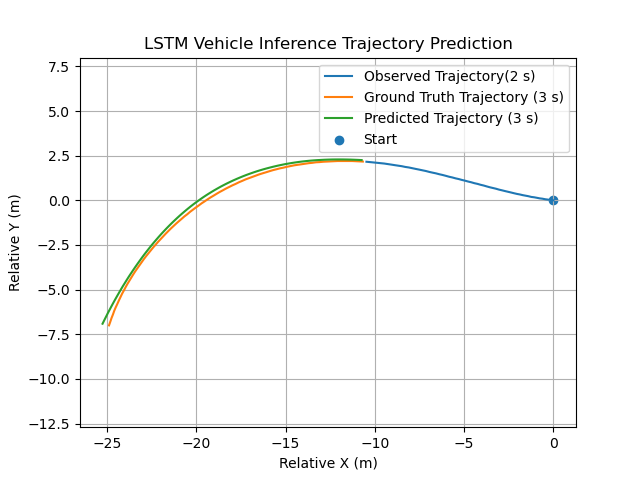

In [108]:
import matplotlib.pyplot as plt
plt.close()
plt.plot(observed[:, 0], observed[:, 1], label="Observed Trajectory(2 s)")
plt.plot(actual[:, 0], actual[:, 1], label="Ground Truth Trajectory (3 s)")
plt.plot(predicted[:, 0], predicted[:, 1], label="Predicted Trajectory (3 s)")

plt.scatter(0, 0, label="Start")

plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.title("LSTM Vehicle Inference Trajectory Prediction")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()

In [109]:
#MSE of inference example (lower than validation as this example was hand-picked)
mse = loss_fn(prediction, y_test.to(device))
print("MSE:", mse.item())

MSE: 0.020125122740864754


## Inspection of Metadata for Mapping Trajectory to Real World (Solely for Visualisation Purposes)

In [28]:
objid, start = test_metadata[test_vehicle_index]

print("Vehicle:", objid)
print("Starting frame:", start)

Vehicle: 61651
Starting frame: 100


In [29]:
vehicle = df[df["OBJID"] == objid]

positions = vehicle[["UTM_X", "UTM_Y"]].values

origin = positions[start]

observed_utm = positions[start:start + 60]

actual_utm = positions[start + 60:start + 150]

print(observed_utm[0])
print(actual_utm[-1])

print(actual_utm[-1] - observed_utm[0])

[ 617371.93 5806809.69]
[ 617382.44 5806776.77]
[ 10.51 -32.92]


## Implementing Cyclist Class with Trajectory

In [30]:
#cyclist class for instantiating a cyclist with state and trajectory for comparing against vehicle trajectory
class Cyclist:
    #parameters will be randomised during inference
    def __init__(self, position: tuple, speed: float, direction: float):
        self.position = position #tuple of x,y location 
        self.speed = speed/3.6 #paramater of speed in km/h converted to m/s
        self.direction = np.deg2rad(direction) #parameter of direction in degrees converted to radians
        self.trajectory = self.create_trajectory()

    def create_trajectory(self):
        trajectory = []
        
        for i in range (0, 150):
            next_position = (self.position[0] + self.speed * np.cos(self.direction) * i/30, self.position[1] + self.speed * np.sin(self.direction) * i/30) 
            trajectory.append(next_position) 

        return trajectory
    
    def get_trajectory(self):
        return np.array(self.trajectory)

    def get_direction(self):
        return np.rad2deg(self.direction)

    def get_speed(self):
        return self.speed

## Visualising Cyclist Trajectory

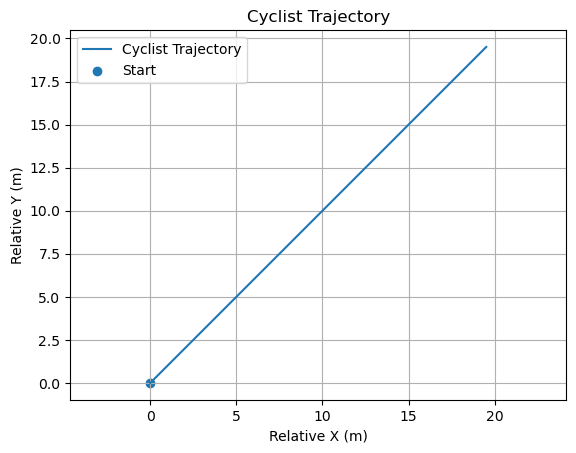

In [31]:
#Validation
import matplotlib.pyplot as plt

#Testing cyclist class implementation
cyclist = Cyclist(position=(0, 0), speed=20, direction=45)

#convert trajectory tuple list to numpy array
trajectory = cyclist.get_trajectory()

#extract coords
x = trajectory[:,0]
y = trajectory[:,1]

plt.close('all')

plt.plot(x, y, label = "Cyclist Trajectory")

plt.scatter(0, 0, label="Start")

plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.title("Cyclist Trajectory")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()

## Defining Time to Collision (TTC) Function

In [32]:
#importing math for euclidean distance calculation
import math

def TTC(cyclist, trajectory, ground_truth):
    #average cyclist and vehicle width according to sources
    vehicle_width = 2.0776
    cyclist_width = 1

    #collision_proximity for ground truth
    collision_proximity = (vehicle_width+cyclist_width)/2

    #increased sensitivity to reduce false negatives
    #higher sensitivity increases amount of false positives, but reduces false negatives (which is higher priority)
    sensitivity = collision_proximity+0.15

    #tolerance used is dependent on whether ground truth or prediction trajectory is used
    if ground_truth:
        tolerance = collision_proximity
    else:
        tolerance = sensitivity
    
    for i in range(len(trajectory)):
        coordinates_distance = trajectory[i] - cyclist.get_trajectory()[i+60]
        euclidean_distance = math.sqrt(coordinates_distance[0]**2 + coordinates_distance[1]**2)
        
        if euclidean_distance <= tolerance:
            return i/30

    return None

## Inference Example Now With Cyclist

In [33]:
#loading in pretrained model
model.load_state_dict(torch.load('4-feature-models/h128_n2_e100_f4.pt', weights_only=True))

<All keys matched successfully>

In [34]:
#predicting the trajectory of one vehicle
vehicle_observed = test_inputs[test_vehicle_index]
vehicle_real = test_targets[test_vehicle_index]

#unsqueeze to allow a single example batch
vehicle_observed = vehicle_observed.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    prediction = model(vehicle_observed)

#remove batch dimension
prediction = prediction.squeeze(0)

#converting tensors to np arrays for plotting
observed = vehicle_observed.squeeze(0).cpu().numpy()
actual = vehicle_real.numpy()
predicted = prediction.cpu().numpy()

In [35]:
#initialising cyclist with specific attributes as it collides with this specific vehicle example
cyclist = Cyclist(position=(4, -50), speed=20, direction=90)

#testing TTC
ttc = TTC(cyclist, predicted, ground_truth= False)  #ground_truth False means calculate TTC with increased sensitivity to crashes
                                                    #(this sensitivity was introduced to reduce false negatives)

if ttc is not None:
    print(f"The TTC is {ttc:0.3f} seconds")
else:
    print("Collision not anticipated")

The TTC is 1.933 seconds


## Graphical Visualisation of Inference Example

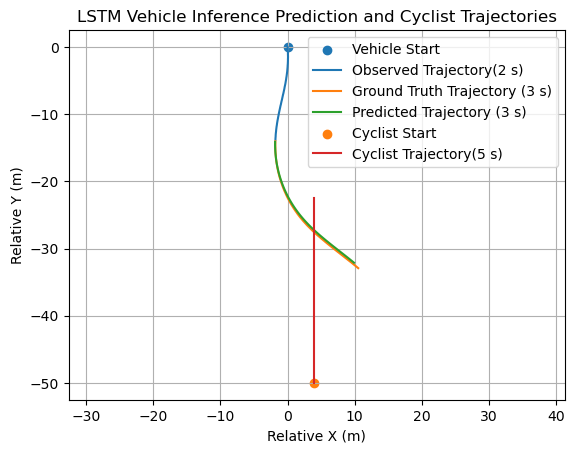

In [36]:
plt.close('all')

plt.scatter(0, 0, label="Vehicle Start")

#Vehicle trajectory segments
plt.plot(observed[:, 0], observed[:, 1], label="Observed Trajectory(2 s)")
plt.plot(actual[:, 0], actual[:, 1], label="Ground Truth Trajectory (3 s)")
plt.plot(predicted[:, 0], predicted[:, 1], label="Predicted Trajectory (3 s)")

plt.scatter(4, -50, label="Cyclist Start")

#Example Cyclist Trajectory
plt.plot(cyclist.get_trajectory()[:,0], cyclist.get_trajectory()[:,1], label="Cyclist Trajectory(5 s)")


plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.title("LSTM Vehicle Inference Prediction and Cyclist Trajectories")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()

## Animation Visualisation of Inference Example

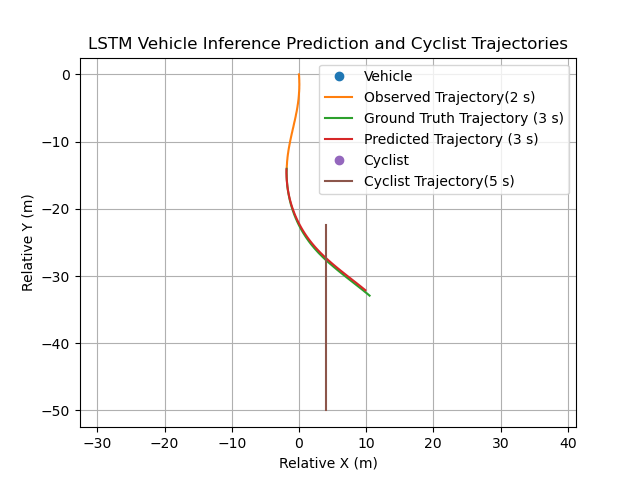

In [40]:
#run at start so reference to past animations is not lost
if 'animation' in globals():
    animation.event_source.stop()

plt.close("all")

#needed for animations in jupyter notebook
%matplotlib widget

#animation library
from matplotlib.animation import FuncAnimation

#create new figure for animation
fig = plt.figure()

#plt.scatter(0, 0, label="Vehicle Start")

#defining animated points
point_v, = plt.plot([], [], 'o', label="Vehicle")

#Vehicle trajectory segments
plt.plot(observed[:, 0], observed[:, 1], label="Observed Trajectory(2 s)")
plt.plot(actual[:, 0], actual[:, 1], label="Ground Truth Trajectory (3 s)")
plt.plot(predicted[:, 0], predicted[:, 1], label="Predicted Trajectory (3 s)")

#defining animated points
point_c, = plt.plot([], [], 'o', label="Cyclist")

#Cyclist Trajectory
trajectory = cyclist.get_trajectory()
plt.plot(trajectory[:, 0], trajectory[:, 1], label="Cyclist Trajectory(5 s)")

#labelling graph
plt.title("LSTM Vehicle Inference Prediction and Cyclist Trajectories")
plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.legend()
plt.grid()
plt.axis('equal')

#combining observed vehicle path and predicted future trajectories
observed_and_predicted = np.vstack((observed[:,:2], predicted))

#updating location of point_c and v for animation
def update(i):
    point_c.set_data([trajectory[i, 0]], [trajectory[i, 1]])
    point_v.set_data([observed_and_predicted[i, 0]], [observed_and_predicted[i, 1]])

    return point_c, point_v

#running animation
animation = FuncAnimation(
    fig,
    update,
    frames=len(trajectory),
    interval=20
)

plt.show()

## Determining Relative Collision Speed

In [41]:
#Defining Relative Collision Function
#RCS measures the magnitude of the difference between two objects’ 
#velocity vectors, accounting for both their speeds and directions of 
#travel to estimate their relative speed at the point of collision
def relativeCollisionSpeed(vehicle_speed: float, cyclist_speed: float, vehicle_angle: float, cyclist_angle: float):
    angle_difference = cyclist_angle - vehicle_angle
    angle_radians = math.radians(angle_difference)

    relative_collision_speed = math.sqrt(
        vehicle_speed**2 +
        cyclist_speed**2 -
        2 * vehicle_speed * cyclist_speed * math.cos(angle_radians)
    )

    return relative_collision_speed

In [42]:
#Vehicle Angle
#getting vehicle position during crash and just before to calculate angle
crash_frame_number = int(ttc*30)
veh_precrash_coord = observed_and_predicted[crash_frame_number+59]
veh_crash_coord = observed_and_predicted[crash_frame_number+60]

#calculating vehicle bearing
veh_crash_angle = np.rad2deg(math.atan2(veh_crash_coord[0] - veh_precrash_coord[0], veh_crash_coord[1] - veh_precrash_coord[1]))

#changing angle to measure from the horizontal
veh_crash_angle -= 90

#measuing anticlockwise
veh_crash_angle *= -1
print(f"Vehicle angle at point of collision is: {veh_crash_angle} (relative to the horizontal)")

#Vehicle Speed (m/s)
vehicle_distance = veh_crash_coord - veh_precrash_coord
veh_crash_speed = math.sqrt(vehicle_distance[0]**2 + vehicle_distance[1]**2) * 30 #multiply by 30 as vehicle is sampled at 30Hz 

#Cyclist Angle
cyc_crash_angle = cyclist.get_direction()
print(f"Cyclist angle at point of collision is: {cyc_crash_angle} (relative to the horizontal)")

#Cyclist Speed (m/s)
cyc_crash_speed = cyclist.get_speed()

RCS = relativeCollisionSpeed(veh_crash_speed, cyc_crash_speed, veh_crash_angle, cyc_crash_angle)

print(f"Relative Collision Speed {RCS}")    

Vehicle angle at point of collision is: -44.73979268571557 (relative to the horizontal)
Cyclist angle at point of collision is: 90.0 (relative to the horizontal)
Relative Collision Speed 12.143522829246349


## Determining Severity and Warning Cyclist

In [43]:
#Crash is severe if it is at high speed and there is insufficient time to react
ttc = TTC(cyclist, predicted, False) #ground_truth False means calculate TTC with increased sensitivity to crashes 
                                     #(this sensitivity was introduced to reduce false negatives)

#time to safely perceive a dangerous event and react is 2.5 seconds (AASHTO green book, 2018)
perception_reaction_time = 2.5

#dangerous speed is the speed at which collisions result in > 10% chance of fatality. This is 30kmh (Harding Mazzotti, 2026)
dangerous_speed = 30/3.6

print(f"TTC: {ttc}")
print(f"RCS: {RCS}")

if ttc is not None:
    if ttc <= perception_reaction_time:
        print("Not enough time for standard perception-reaction.")
        if RCS >= dangerous_speed: 
            print("Collision anticipated at or above dangerous speed.")
            print(f"WARNING HIGH RISK COLLISION ANTICIPATED")

TTC: 1.9333333333333333
RCS: 12.143522829246349
Not enough time for standard perception-reaction.
Collision anticipated at or above dangerous speed.
WARNING HIGH RISK COLLISION ANTICIPATED


# Correctness Evaluation on Test Data 

In [74]:
#run all test inputs through the model 
#then run all through crash detected
#if collisions detected in prediction and not target or vice versa increment false pos/neg counter

model.load_state_dict(torch.load('4-feature-models/h128_n2_e100_f4.pt', weights_only=True))

evaluate_accuracy = True

if evaluate_accuracy:
    #running test data through model on eval, no gradient mode
    model.eval()

    test_predictions = []
    test_actual_trajectories = []

    with torch.no_grad():

        for x_batch, y_batch in test_loader:
    
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
    
            prediction = model(x_batch)
    
            test_predictions.extend(prediction.cpu().numpy())
            test_actual_trajectories.extend(y_batch.cpu().numpy())

## Function for Determining is Crash Occurs

In [111]:
#importing math for euclidean distance calculation
import math

def isCrashDetected(cyclist: Cyclist, trajectory, ground_truth):
    #average cyclist and vehicle width according to sources
    vehicle_width = 2.0776
    cyclist_width = 1

    #collision_proximity for ground truth
    collision_proximity = (vehicle_width+cyclist_width)/2

    #increased sensitivity to improve false pos to false negative balance
    #increasing this value increases change of false_positive, but reduces false negatives (which is higher priority)
    sensitivity = collision_proximity+0.15

    #tolerance used is dependent on whether ground truth or prediction trajectory is used
    if ground_truth:
        tolerance = collision_proximity
    else:
        tolerance = sensitivity
    
    for i in range(len(trajectory)):
        coordinates_distance = trajectory[i] - cyclist.get_trajectory()[i+60]
        euclidean_distance = math.sqrt(coordinates_distance[0]**2 + coordinates_distance[1]**2)
        
        if euclidean_distance <= tolerance:
            return True

        #function gets to here when collision not detected
        return False

## Function for Generating Random Cyclist (with higher tendency for collisions)

In [112]:
import numpy as np
import random
import math

def generate_cyclist(actual_trajectory, collision_probability=0.5):

    #random speed and direction
    speed = random.uniform(5, 30)  # km/h
    direction = random.uniform(0, 360)  # degrees

    #execute this half the time
    if random.random() < collision_probability:

        #pick a future frame to approach the vehicle
        frame = random.randint(0, 89)

        #get the vehicle position at this future frame
        collision_point = actual_trajectory[frame]

        #time from beginning of observation to collision
        time = (60 + frame) / 30

        #cyclist displacement over this time
        speed_ms = speed / 3.6
        angle_rad = math.radians(direction)

        #calculate necessary cyclist angle to hit collision point
        dx = speed_ms * math.cos(angle_rad) * time
        dy = speed_ms * math.sin(angle_rad) * time

        #calculate cyclist starting position
        start_x = collision_point[0] - dx
        start_y = collision_point[1] - dy

        #add noise to create collisions and near misses
        start_x += random.uniform(-2, 2)
        start_y += random.uniform(-2, 2)

        position = (start_x, start_y)

    else:
        #original random cyclist generation half the time
        position = (
            random.uniform(-20, 20),
            random.uniform(-20, 20)
        )

    return Cyclist(position, speed, direction)

## Testing Predicted Trajectories Ability to Match Ground Truth for Collision Detection   

In [113]:
#generate random cyclist for each trajectory and check if collision occurs between cyclist and predicted trajectory
#and compare if collision occurs between cycist and actual trajectory 
random.seed(1)

#keep count of true and false positive and negatives
false_positives = 0
false_negatives = 0
true_positives = 0
true_negatives = 0

for traj in range(len(test_predictions)):

    #instantiate cyclist with random attributes, but slight tendency for collisions 
    cyclist = generate_cyclist(test_actual_trajectories[traj], collision_probability=0.5)

    #check if collsions occurs based on prediction and based on reality
    crash_predicted = isCrashDetected(cyclist, test_predictions[traj], False) #run with ground_truth = False
    crash_occurs = isCrashDetected(cyclist, test_actual_trajectories[traj], True) #run with ground_truth = True

    #increment appropriate false counters 
    if(crash_predicted and  not crash_occurs):
        false_positives += 1
    
    elif(not crash_predicted and crash_occurs):
        false_negatives += 1       

    #increment appropriate true counters
    if(crash_predicted and crash_occurs):
        true_positives += 1
    
    elif(not crash_predicted and not crash_occurs):
        true_negatives += 1       

## Printing Evaluation Metrics

In [117]:
print(f"Instances: {true_negatives + false_positives + true_positives + false_negatives}")
print(f"Collisions: {true_positives + false_negatives}")
print()

print(f"False Positives: {false_positives}")
print(f"False Negatives: {false_negatives}")
print(f"True Positives: {true_positives}")
print(f"True Negatives: {true_negatives}")
print()

#these evaluation metrics relate to whether a crash will be correctly flagged based on trajectory prediction
print("Evaluation Metrics:")

#calculating metrics
#out of all collisions, what % were correctly predicted
recall = true_positives/(true_positives + false_negatives)*100

#out of all predicted collsions, what % were correct
precision = true_positives/(true_positives + false_positives)*100

#harmonic mean of precision and recall
f1_score = 2*recall*precision/(recall+precision)

false_positive_rate = false_positives / (false_positives + true_negatives) * 100
false_negative_rate = false_negatives / (false_negatives + true_positives) * 100

#printing metrics
print(f"Recall: {recall:0.5}%")
print(f"Precision: {precision:0.5}%")
print(f"F1 Score: {f1_score:0.5}%")
print(f"False Positive Rate: {false_positive_rate:0.5}%")
print(f"False Negative Rate: {false_negative_rate:0.5}%")

Instances: 13515
Collisions: 397

False Positives: 115
False Negatives: 2
True Positives: 395
True Negatives: 13003

Evaluation Metrics:
Recall: 99.496%
Precision: 77.451%
F1 Score: 87.1%
False Positive Rate: 0.87666%
False Negative Rate: 0.50378%
